# Lab_8

# Lucian Valle Aguilar
# 1066866114

In [1]:
import pandas as pd
import scipy as sc
import numpy as np
import h5py
import matplotlib.pylab as plt

In [2]:
data_train= "train_catvnoncat.h5"
train_dataset = h5py.File(data_train, "r")

data_test= "test_catvnoncat.h5"
test_dataset = h5py.File(data_test, "r")

In [3]:
xtrain_classes, xtrain, train_label =\
train_dataset["list_classes"],train_dataset["train_set_x"],train_dataset["train_set_y"]

test_classes, xtest,test_label =\
test_dataset["list_classes"],test_dataset["test_set_x"],test_dataset["test_set_y"]


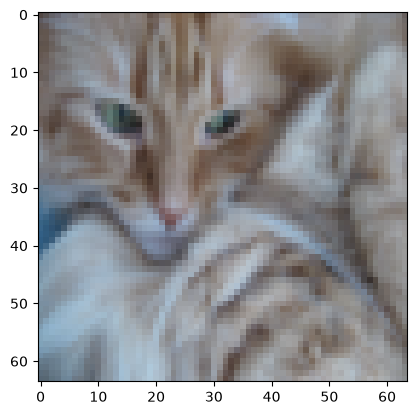

In [4]:
plt.imshow(xtrain[2])

## 1.  
Construir un clase  que permita definir una red neuronal con la topología
deseada y la función de activación para cada capa, para ello deberá construir una funcion Topology con el número de capas de la red neuronal :

Topology = [n_x, n_h1, n_h2, n_h3, ...,n_y]

En este caso:
- $n^{[0]}=n_x$ seran los valores de entradas de la capa de entrada
- $n^{[1]}=n_{h1}$ Primera capa oculta de la red neuronal
- $n^{[2]}=n_{h2}$ Segunda capa oculta de la red neuronal

.

.

.


- $n^{[l]}=n_{hl}$ Segunda capa oculta de la red neuronal
.

.

.

- $n^{[L]}=n_{y}$ Segunda capa oculta de la red neuronal

donde

- $\mathrm{n_x}$: valores de entrada
- $\mathrm{n_{h1}}$: hidden layer 1
- $\mathrm{n_{h2}}$: hidden layer 2
- $\mathrm{n_y}$: last layer

- $n^{[L]}=n_{y}$ Segunda capa oculta de la red neuronal


También definir una lista con las funciones de activaciones para cada capa.


activation=[None, relu, relu, relu, ...,sigmoid]

  


a. Cada unas de las capas deberá tener los parámetros de inicialización de manera aleatoria:


La matriz de parametros para cada capa debera tener:


$\mathrm{dim(\vec{b}^{[l]})}=n^{[l]}$

$\mathrm{dim(\vec{\Theta}^{[l]})}=n^{[l]}\times n^{[l-1]}$

Lo anteriores parametros deberán estar en el constructor de la clase.


b. Construya un metodo llamado output cuya salida serán los valores de Z y A


$\mathrm{dim(\vec{\cal{A}}^{[l]})}=n^{[l-1]}\times m $

$\mathrm{dim(\vec{\cal{Z}}^{[l]})}=n^{[l]}\times m $.

In [ ]:
# funcion activacion y clases

import numpy as np

def act_function(x, activation):
    if activation == "sigmoid":
        f = 1 / (1 + np.exp(-x))
        fp = f * (1 - f)
        return f, fp
    elif activation == "relu":
        f = np.maximum(0, x)
        fp = np.where(x > 0, 1.0, 0.0)
        return f, fp
    elif activation == "tanh":
        f = np.tanh(x)
        fp = 1 - f**2
        return f, fp
    elif activation == None:
        return x, np.ones_like(x)
    else:
        raise ValueError(f"Función de activación '{activation}' no soportada.")

class layer_nn():
    def __init__(self, nlayer_present, nlayer_before, act_fun="sigmoid"):
        # Inicialización aleatoria de pesos (theta) y sesgos (B)
        self.theta = 2 * np.random.random((nlayer_present, nlayer_before)) - 1
        self.B = 2 * np.random.random((nlayer_present, 1)) - 1
        self.act_fun = act_fun
        self.Z = None
        self.A = None
        self.Ap = None

    def output(self, X):
        # Z = Theta * X + B
        self.Z = np.dot(self.theta, X) + self.B
        self.A, self.Ap = act_function(self.Z, self.act_fun)
        return self.A

In [11]:
np.shape(xtrain[0])

(64, 64, 3)

In [12]:
np.reshape(xtrain[0], 64*64*3)

array([17, 31, 56, ...,  0,  0,  0], shape=(12288,), dtype=uint8)

In [13]:
xtrain_= np.reshape(xtrain,(209, 64*64*3))/255
xtest_ = np.reshape(xtest,(50, 64*64*3))/255

In [14]:
l_input = len(xtrain_[208])

## 2. 
Construir un generalizacion de la red, en el que entrada el valor inicial y la red neuronal completa arroje la salida y la actualizacion de la red con los parametros deseados:

  ```
  A, nn = forward_pass(A0, nn_red)

 ```2. Construir un generalizacion de la red, en el que entrada el valor inicial
y la red neuronal completa arroje la salida y la actualizacion de la red con los parametros deseados:

  ```
  A, nn = forward_pass(A0, nn_red)

 ```

In [17]:
def forward_pass(A0, nn_red):
    A = A0
    for layer in nn_red:
        A = layer.output(A)
    return A, nn_red

## 3. 
Encontrar la funcion de coste.


$$-\frac{1}{m} \sum\limits_{i = 1}^{m} (y^{(i)}\log\left(a^{[L] (i)}\right) + (1-y^{(i)})\log\left(1- a^{[L](i)}\right)) \tag{7}$$

In [6]:
def FuncionCoste(AL, Y):
    m = Y.shape[1]
    # Se agrega 1e-15 para evitar log(0)
    AL_bounded = np.clip(AL, 1e-15, 1 - 1e-15)
    cost = -(1 / m) * np.sum(Y * np.log(AL_bounded) + (1 - Y) * np.log(1 - AL_bounded))
    return np.squeeze(cost)

## 4. 
Construir un codigo que permita realizar el BackwardPropagation


# Backward Propagation

Para una capa $l$ arbitraria tenemos que:

- \begin{equation}
d\Theta^{[l]} =  d{\cal Z}^{(i)[l]} Trans(A)^{(i)[l-1]} = dA^{(i)[l]} f'({\cal Z}^{(i)[l]} ) Trans(A)^{(i)[l-1]}
\end{equation}

- \begin{equation}
db^{[l]} =  d{\cal Z}^{(i)[L]}  = dA^{(i)[l]} f'({\cal Z}^{(i)[l]} )
\end{equation}
```
db_L =  m_*np.sum(dZ, axis=1, keepdims=True)
```
Los valores de dA pueden ser escritos como:
- \begin{equation}
dA^{(i)[l-1]} = \Theta^{l} \cdot dZ^{(i)[l]}
\end{equation}

In [18]:
def backward_propagation(AL, Y, nn_red, A0):
    m = Y.shape[1]
    L = len(nn_red)
    grads = {}
    
    # Derivada inicial de la función de coste respecto a AL
    dAL = -(np.divide(Y, np.clip(AL, 1e-15, 1 - 1e-15)) - np.divide(1 - Y, np.clip(1 - AL, 1e-15, 1 - 1e-15)))
    
    dA_current = dAL
    
    for l in reversed(range(L)):
        layer = nn_red[l]
        A_prev = A0 if l == 0 else nn_red[l-1].A
        
        # dZ = dA * f'(Z)
        dZ = dA_current * layer.Ap
        
        # dTheta y dB
        dTheta = (1 / m) * np.dot(dZ, A_prev.T)
        dB = (1 / m) * np.sum(dZ, axis=1, keepdims=True)
        
        # dA para la capa previa
        dA_current = np.dot(layer.theta.T, dZ)
        
        grads[f"dTheta_{l}"] = dTheta
        grads[f"dB_{l}"] = dB
        
    return grads

def update_parameters(nn_red, grads, learning_rate):
    L = len(nn_red)
    for l in range(L):
        nn_red[l].theta -= learning_rate * grads[f"dTheta_{l}"]
        nn_red[l].B -= learning_rate * grads[f"dB_{l}"]
    return nn_red

In [9]:
xtrain_= np.reshape(xtrain,(209, 64*64*3))/255
xtest_ = np.reshape(xtest,(50, 64*64*3))/255

In [22]:
# 1. Preparar datos
# xtrain_ tiene forma (209, 12288) -> Transponemos a (12288, 209)
X_train = xtrain_.T
train_label_shape = np.reshape(train_label, (1, -1)) 
Y_train = train_label_shape

# 2. Definir Topología y construir la Red Neuronal
topology = [12288, 64, 16, 1]
activations = ["relu", "relu", "sigmoid"]

nn_red = []
for i in range(len(topology) - 1):
    layer = layer_nn(nlayer_present=topology[i+1], 
                     nlayer_before=topology[i], 
                     act_fun=activations[i])
    nn_red.append(layer)

# 3. Bucle de Entrenamiento (Gradient Descent)
epochs = 2000
learning_rate = 0.005
cost_history = []

for epoch in range(epochs):
    # Forward pass
    AL, nn_red = forward_pass(X_train, nn_red)
    
    # Calcular Coste
    cost = FuncionCoste(AL, Y_train)
    cost_history.append(cost)
    
    # Backward pass
    grads = backward_propagation(AL, Y_train, nn_red, X_train)
    
    # Actualizar Parámetros
    nn_red = update_parameters(nn_red, grads, learning_rate)
    
    if epoch % 200 == 0:
        print(f"Época {epoch} - Coste: {cost:.4f}")

# 4. Evaluación en Test
X_test = xtest_.T
test_label_shape = np.reshape(test_label, (1, -1))
Y_test = test_label_shape

AL_test, _ = forward_pass(X_test, nn_red)
predictions = (AL_test > 0.5).astype(int)
accuracy = np.mean(predictions == Y_test) * 100
print(f"\nPrecisión en el conjunto de prueba (Test Accuracy): {accuracy:.2f}%")

Época 0 - Coste: 11.2370
Época 200 - Coste: 10.7418
Época 400 - Coste: 10.7418
Época 600 - Coste: 10.7418
Época 800 - Coste: 10.7417
Época 1000 - Coste: 10.7417
Época 1200 - Coste: 10.7417
Época 1400 - Coste: 10.7417
Época 1600 - Coste: 10.7417
Época 1800 - Coste: 10.7417

Precisión en el conjunto de prueba (Test Accuracy): 36.00%
